# Task 1: Meshed AC-DC example

This notebook runs the [meshed AC-DC example](https://docs.pypsa.org/latest/examples/ac-dc-lopf/) from the PyPSA documentation, describes what the system is made of, and explains why Frankfurt Gas is dispatched at 05:00 on 1 January 2015 while the Norway and Manchester gas plants are not.

In [1]:
import logging, warnings
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

warnings.filterwarnings("ignore")
logging.getLogger("pypsa").setLevel(logging.ERROR)
logging.getLogger("linopy").setLevel(logging.ERROR)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
SOLVER = "highs"  # free solver, installed with: pip install highspy

In [2]:
def load_network():
    """Meshed AC-DC example, exactly as in the PyPSA documentation."""
    n = pypsa.examples.ac_dc_meshed()
    n.links.loc["Norwich Converter", "p_nom_extendable"] = False
    return n

def total_cost(n):
    return n.objective + n.objective_constant

n = load_network()
n.optimize(solver_name=SOLVER, log_to_console=False)
print(f'Total system cost: {total_cost(n):,.0f} EUR')

Total system cost: 18,440,973 EUR


## 1.1 What the system is made of

The network has an AC part and a DC part, joined by converters:

* **9 buses**: 6 AC buses (London, Norwich, Manchester, Bremen, Frankfurt, Norway) and 3 DC buses (Norwich DC, Bremen DC, Norway DC).
* **7 lines**: 4 AC lines (London-Manchester, Manchester-Norwich, Norwich-London in the UK, Bremen-Frankfurt in Germany) and 3 DC lines that form a meshed DC triangle between Norwich DC, Bremen DC and Norway DC.
* **4 links**: three AC-DC converters (Norwich, Bremen, Norway) and one point-to-point HVDC link from London to Bremen.
* **6 generators**: one wind farm and one gas plant at each of Manchester, Norway and Frankfurt.
* **6 loads**, one at every AC bus.
* **10 hourly snapshots** (00:00 to 09:00 on 1 January 2015) and **one global constraint**: total CO2 emissions must stay below 1000 t.

In [3]:
n.determine_network_topology()
print(n.buses[['carrier', 'v_nom', 'sub_network']])
print()
lines = n.lines[['bus0', 'bus1']].copy()
lines['type'] = n.lines.bus0.map(n.buses.carrier)
print(lines)
print()
print(n.links[['bus0', 'bus1', 'p_nom', 'p_nom_extendable']])
print()
print(n.global_constraints[['type', 'carrier_attribute', 'sense', 'constant']])

           carrier  v_nom sub_network
name                                 
London          AC  380.0           0
Norwich         AC  380.0           0
Norwich DC      DC  200.0           1
Manchester      AC  380.0           0
Bremen          AC  380.0           2
Bremen DC       DC  200.0           1
Frankfurt       AC  380.0           2
Norway          AC  380.0           3
Norway DC       DC  200.0           1

            bus0        bus1 type
name                             
0         London  Manchester   AC
1     Manchester     Norwich   AC
2      Bremen DC  Norwich DC   DC
3     Norwich DC   Norway DC   DC
4      Norway DC   Bremen DC   DC
5        Norwich      London   AC
6         Bremen   Frankfurt   AC

                      bus0        bus1   p_nom  p_nom_extendable
name                                                            
Norwich Converter  Norwich  Norwich DC  1000.0             False
Norway Converter    Norway   Norway DC  1000.0              True
Bremen Convert

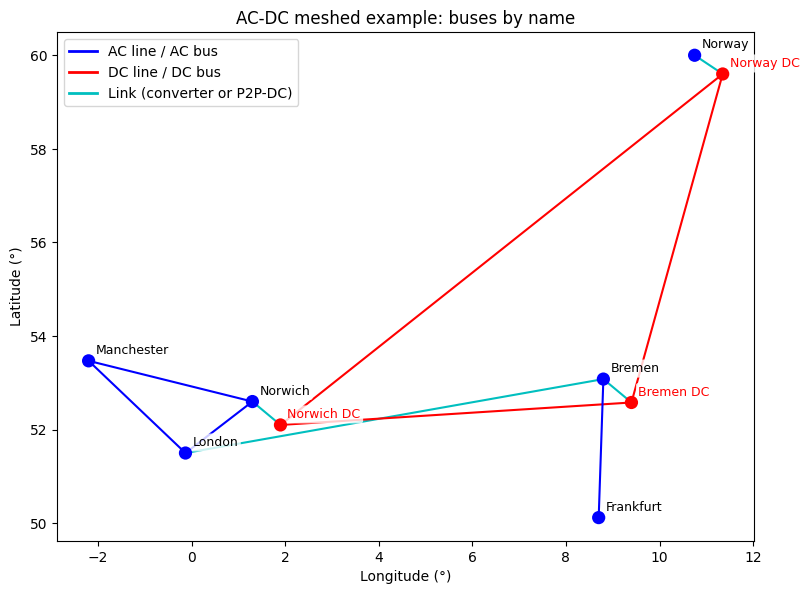

In [5]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
m=n
is_dc = m.buses.carrier == "DC"
m.buses.loc[is_dc, "x"] += 0.6          # degrees east
m.buses.loc[is_dc, "y"] -= 0.4          # degrees south
 
# ---- 2. Colours ----
line_color = m.lines.bus0.map(m.buses.carrier).map({"AC": "b", "DC": "r"})
bus_color  = m.buses.carrier.map({"AC": "b", "DC": "r"})
 
# ---- 3. Plot the network ----
fig, ax = plt.subplots(figsize=(9, 8))
m.plot(ax=ax, geomap=False,
       bus_color=bus_color, line_color=line_color, link_color="c")
 
# ---- 4. Label every bus with its name ----
for name, b in m.buses.iterrows():
    ax.text(b.x + 0.15, b.y + 0.15, name, fontsize=9,
            color="r" if b.carrier == "DC" else "k",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
 
# ---- 5. Legend, title, axes ----
ax.legend(handles=[Line2D([], [], color="b", lw=2, label="AC line / AC bus"),
                   Line2D([], [], color="r", lw=2, label="DC line / DC bus"),
                   Line2D([], [], color="c", lw=2, label="Link (converter or P2P-DC)")],
          loc="upper left")
ax.set_title("AC-DC meshed example: buses by name")
ax.set_axis_on()
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
plt.savefig("acdc_map.png", dpi=150, bbox_inches="tight")
plt.show()
# print(m.buses[["x", "y", "carrier"]])

## 1.2 Size of the generators

All six generators are **extendable**, so their size is an output of the optimisation, not an input. The `p_nom` values stored in the file (80 to 80,000 MW) are only starting points. What constrains the investment is `p_nom_min` (each wind farm must be at least 100 MW, the gas plants can be built from zero) and the costs. The table shows the inputs next to the optimised capacities `p_nom_opt`.

In [6]:
gen = n.generators[["bus", "carrier", "p_nom", "p_nom_min", "capital_cost", "marginal_cost", "efficiency"]].copy()
gen["p_nom_opt [MW]"] = n.generators.p_nom_opt
gen["energy [MWh]"] = n.generators_t.p.sum()
gen["avg p_max_pu"] = n.generators_t.p_max_pu.mean().reindex(gen.index)
gen.round(3)

,bus,carrier,p_nom,p_nom_min,capital_cost,marginal_cost,efficiency,p_nom_opt [MW],energy [MWh],avg p_max_pu
name,,,,,,,,,,
Manchester Wind,Manchester,wind,80.0,100.0,2793.652,0.110,1.000,4090.810,16218.005,0.532
Manchester Gas,Manchester,gas,50000.0,0.0,196.615,4.532,0.350,0.000,0.000,NaN
Norway Wind,Norway,wind,100.0,100.0,2184.375,0.090,1.000,1533.600,7725.115,0.504
Norway Gas,Norway,gas,20000.0,0.0,158.251,5.893,0.357,0.000,0.000,NaN
Frankfurt Wind,Frankfurt,wind,110.0,100.0,2129.456,0.100,1.000,1667.724,7139.233,0.428
Frankfurt Gas,Frankfurt,gas,80000.0,0.0,102.677,4.086,0.352,982.034,1465.274,NaN


**Result.** The optimiser builds roughly **4.1 GW of wind at Manchester, 1.5 GW at Norway and 1.7 GW at Frankfurt**, plus **about 980 MW of gas at Frankfurt**. Manchester Gas and Norway Gas are built at **0 MW**. Total installed capacity is about 8.3 GW against a peak load of 4.3 GW. The overbuild is deliberate. Wind output varies a lot from hour to hour, so extra wind capacity is needed to cover the low-wind hours, and some of it gets curtailed in windy hours (see Task 2).

## 1.3 Why Frankfurt Gas runs at 05:00 and the other gas plants do not

**Step 1: why any gas is needed at 05:00.** At 05:00 the load is at its highest (4,344 MW) and Norway Wind is almost still (`p_max_pu` = 0.0097). Even with every wind farm producing everything it can, wind only covers about 3,360 MW. The remaining gap of about 980 MW has to come from gas.

In [7]:
t = "2015-01-01 05:00"
wind = n.generators.index[n.generators.carrier == "wind"]
avail = (n.generators_t.p_max_pu.loc[t, wind] * n.generators.p_nom_opt[wind])
print("Load at 05:00             :", round(n.loads_t.p_set.loc[t].sum(), 1), "MW")
print("Wind available at 05:00   :", round(avail.sum(), 1), "MW")
print("Wind actually dispatched  :", round(n.generators_t.p.loc[t, wind].sum(), 1), "MW (no curtailment)")
print("Gap filled by gas         :", n.generators_t.p.loc[t].round(1)[n.generators.carrier == 'gas'].to_dict())

Load at 05:00             : 4343.6 MW
Wind available at 05:00   : 3361.6 MW
Wind actually dispatched  : 3361.6 MW (no curtailment)
Gap filled by gas         : {'Manchester Gas': -0.0, 'Norway Gas': -0.0, 'Frankfurt Gas': 982.0}


**Step 2: why the gap is filled from Frankfurt.** The model is a single linear programme that minimises total cost, which is capital cost plus operating cost. The CO2 cap of 1000 t is binding. Gas therefore only runs for about 1,465 MWh over the whole 10 hours, and the gas plant is in effect a peaking plant. For a peaker, the capital cost per MW decides the choice:

| | Capital cost (EUR/MW) | Marginal cost (EUR/MWh) | CO2 intensity (t/MWh_el) |
|---|---|---|---|
| **Frankfurt Gas** | **102.7** | **4.09** | 0.683 |
| Norway Gas | 158.3 | 5.89 | **0.673** |
| Manchester Gas | 196.6 | 4.53 | 0.686 |

* **Manchester Gas** is worse than Frankfurt Gas on all three counts: more expensive to build, more expensive to run, and more CO2 per MWh. It is never chosen.
* **Norway Gas** has the highest efficiency, so it emits slightly less CO2 per MWh and could produce slightly more energy under the cap. That small advantage does not make up for a capital cost about 55% higher than Frankfurt Gas. Building about 980 MW in Norway instead of Frankfurt would cost roughly 55,000 EUR more in capacity alone.
* **The network is not the reason.** At 05:00 the nodal prices are almost the same everywhere (about 1,594 EUR/MWh), so transmission is not forcing gas to sit in Frankfurt. In fact Frankfurt exports at 05:00 over the Bremen-Frankfurt line, which is running at its limit.

The check below confirms this. If Frankfurt Gas is not allowed to be built, the optimiser builds Norway Gas instead and total system cost rises by about 26,000 EUR.

In [8]:
g = n.generators[n.generators.carrier == "gas"]
co2_price = -n.global_constraints.mu["co2_limit"]
cmp = pd.DataFrame({
    "capital_cost": g.capital_cost,
    "marginal_cost": g.marginal_cost,
    "t_CO2_per_MWh_el": 0.24 / g.efficiency,
    "marginal_cost_incl_CO2_shadow_price": g.marginal_cost + co2_price * 0.24 / g.efficiency,
})
print(f"CO2 shadow price: {co2_price:,.0f} EUR/t")
print(cmp.round(3))
print()
print("Nodal prices at 05:00 [EUR/MWh]:")
print(n.buses_t.marginal_price.loc[t].round(2))
print()
print("Line loading at 05:00 (flow / capacity):")
print((n.lines_t.p0.loc[t] / n.lines.s_nom_opt).round(2))

CO2 shadow price: 2,178 EUR/t
                capital_cost  marginal_cost  t_CO2_per_MWh_el  marginal_cost_incl_CO2_shadow_price
name                                                                                              
Manchester Gas       196.615          4.532             0.686                             1498.197
Norway Gas           158.251          5.893             0.673                             1471.052
Frankfurt Gas        102.677          4.086             0.682                             1490.788

Nodal prices at 05:00 [EUR/MWh]:
name
London        1593.66
Norwich       1593.66
Norwich DC    1593.66
Manchester    1593.66
Bremen        1593.66
Bremen DC     1593.66
Frankfurt     1593.46
Norway        1593.66
Norway DC     1593.66
Name: 2015-01-01 05:00:00, dtype: float64

Line loading at 05:00 (flow / capacity):
name
0   -0.76
1    0.83
2   -0.20
3    0.75
4   -0.37
5    0.05
6   -1.00
dtype: float64


In [9]:
m = load_network()
m.generators.loc["Frankfurt Gas", "p_nom_max"] = 0
m.optimize(solver_name=SOLVER, log_to_console=False)
print("Gas capacity built without Frankfurt Gas [MW]:")
print(m.generators.p_nom_opt[m.generators.carrier == "gas"].round(1))
print(f"Increase in total system cost: {total_cost(m) - total_cost(n):,.0f} EUR")

Gas capacity built without Frankfurt Gas [MW]:
name
Manchester Gas      0.0
Norway Gas        991.9
Frankfurt Gas       0.0
Name: p_nom_opt, dtype: float64
Increase in total system cost: 26,274 EUR


**Summary.** 05:00 is the hour with the highest demand and the lowest wind, so it is the hour that sets the size of the gas plant. Because the CO2 cap limits gas to a few hundred MWh of peaking duty, the cheapest plant to build wins, and that is Frankfurt Gas. It also has the lowest fuel cost. Norway Gas is only slightly cleaner, and Manchester Gas is worse on every measure, so neither is built, and a plant with zero capacity cannot be dispatched.